# 00: Exploring PathMNIST

Before training anything, we want to know what the data looks like: what the images show, how many there are of each kind, what the pixel values are, and whether the test set looks like the training set. Every surprise we find here is a surprise we will not have later.

## What is histology, and what is H&E staining?

**Histology** is the study of tissue under a microscope. A surgeon removes a piece of tissue (here, from the colon), a lab slices it a few micrometers thin, and puts the slice on a glass slide. Unstained tissue is nearly transparent, so the slice is dyed.

**H&E** is the most common stain combination in pathology:

* **Hematoxylin** stains cell **nuclei** (where the DNA lives) dark **blue or purple**.
* **Eosin** stains **cytoplasm** and the fibers between cells **pink**.

So in every image below, purple dots are mostly nuclei and pink areas are mostly cell bodies and connective tissue. A pathologist reads patterns in these colors and shapes: how crowded the nuclei are, how regular the structures look, and so on.

The slides are scanned into huge digital images and cut into small square **patches**. PathMNIST comes from the NCT CRC HE 100K dataset (colorectal cancer patches, 224 by 224 pixels originally), shrunk down to **28 by 28 pixels**. That is very low resolution, so a lot of fine detail is gone. We will keep that limitation in mind.

## Setup

This cell finds the project root (the folder that contains `src/`) so the notebook works no matter which folder Jupyter was started from.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir():
    if ROOT.parent == ROOT:
        raise RuntimeError("Could not find the project root. Start Jupyter inside the project folder.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import CLASS_NAMES, SPLITS, class_count_table, load_all_splits

FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# One color per split, used in every chart so a split always has the same color.
SPLIT_COLORS = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#b5b4ad", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10,
})
print("Project root found:", ROOT.name)

Project root found: trustworthy_tissue_classifier


In [2]:
data = load_all_splits()
for split in SPLITS:
    images, labels = data[split]
    print(f"{split:>5}: {len(labels):>6} images")

train:  89996 images
  val:  10004 images
 test:   7180 images


## The 9 tissue classes

| Label | Class | What it is |
|---|---|---|
| 0 | adipose | Fat tissue. Big, mostly empty looking cells, so the patch is mostly white with thin pink walls. |
| 1 | background | Areas without usable tissue. Some are pale empty slide, but many are dark, blurry, or edge regions (you will see this in the example grid below). |
| 2 | debris | Dead cells and fragments (necrosis). Messy, broken up texture. |
| 3 | lymphocytes | Immune cells. Small, round, very dark nuclei packed tightly, so the patch looks densely purple. |
| 4 | mucus | Slimy material the colon secretes. Pale and wispy, often light blue or light pink. |
| 5 | smooth muscle | The muscle layer of the colon wall. Pink, with long stretched out fibers. |
| 6 | normal colon mucosa | The healthy inner lining of the colon, with neat, organized glands. |
| 7 | cancer associated stroma | The connective tissue around a tumor, which changes in response to the cancer. |
| 8 | colorectal adenocarcinoma epithelium | The tumor cells themselves. Crowded, irregular nuclei. |

Class 8 is the cancer itself, and class 7 is tissue reacting to cancer. Telling those apart from normal mucosa and from each other is the clinically interesting part.

In [3]:
for i, name in enumerate(CLASS_NAMES):
    print(i, name)

0 adipose
1 background
2 debris
3 lymphocytes
4 mucus
5 smooth muscle
6 normal colon mucosa
7 cancer-associated stroma
8 colorectal adenocarcinoma epithelium


## How many images of each class are in each split?

This uses `class_count_table` from `src/data.py`. If one class is much more common than the others, a model could score well by mostly guessing that class, so we need to know the balance before we judge accuracy.

In [4]:
counts = class_count_table({split: data[split][1] for split in SPLITS})
counts.loc["total"] = counts.sum()
counts

,train,val,test
class,,,
adipose,9366,1041,1338
background,9509,1057,847
debris,10360,1152,339
lymphocytes,10401,1156,634
mucus,8006,890,1035
smooth muscle,12182,1354,592
normal colon mucosa,7886,877,741
cancer-associated stroma,9401,1045,421
colorectal adenocarcinoma epithelium,12885,1432,1233


In [5]:
percent = class_count_table({split: data[split][1] for split in SPLITS})
percent = (100 * percent / percent.sum()).round(1)
percent

,train,val,test
class,,,
adipose,10.4,10.4,18.6
background,10.6,10.6,11.8
debris,11.5,11.5,4.7
lymphocytes,11.6,11.6,8.8
mucus,8.9,8.9,14.4
smooth muscle,13.5,13.5,8.2
normal colon mucosa,8.8,8.8,10.3
cancer-associated stroma,10.4,10.4,5.9
colorectal adenocarcinoma epithelium,14.3,14.3,17.2


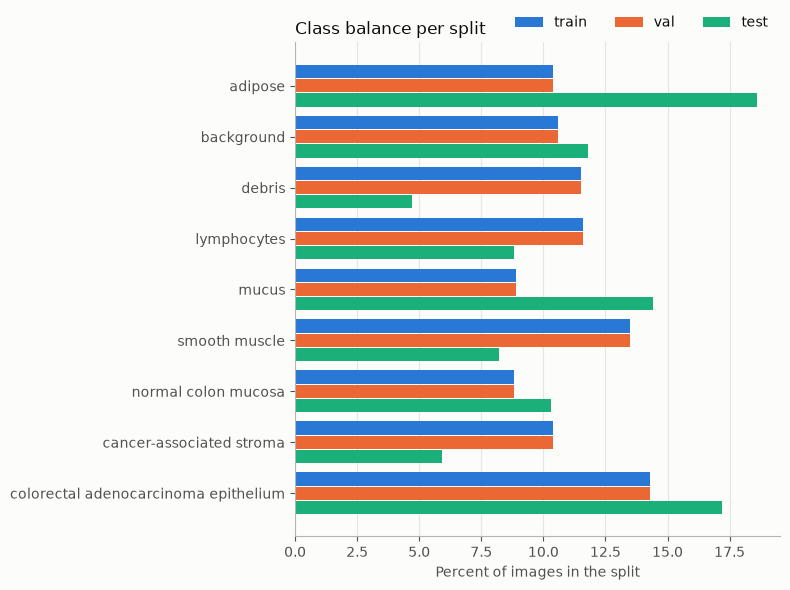

In [6]:
fig, ax = plt.subplots(figsize=(8, 6))
y = np.arange(len(CLASS_NAMES))
bar_height = 0.26
for k, split in enumerate(SPLITS):
    ax.barh(y + (k - 1) * (bar_height + 0.02), percent[split], height=bar_height,
            color=SPLIT_COLORS[split], label=split)
ax.set_yticks(y, CLASS_NAMES)
ax.invert_yaxis()
ax.set_xlabel("Percent of images in the split")
ax.set_title("Class balance per split", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1.0), ncol=3)
fig.tight_layout()
fig.savefig(FIGURES / "class_balance.png", dpi=150)
plt.show()

In [7]:
share_gap = (percent["test"] - percent["train"]).sort_values()
print("Most common class in train:", percent["train"].idxmax(), f"({percent['train'].max()}%)")
print("Least common class in train:", percent["train"].idxmin(), f"({percent['train'].min()}%)")
print("Largest ratio between most and least common train class:",
      round(counts.loc[CLASS_NAMES, "train"].max() / counts.loc[CLASS_NAMES, "train"].min(), 2))
print()
print("Test percent minus train percent, per class:")
print(share_gap.to_string())

Most common class in train: colorectal adenocarcinoma epithelium (14.3%)
Least common class in train: normal colon mucosa (8.8%)
Largest ratio between most and least common train class: 1.63

Test percent minus train percent, per class:
class
debris                                 -6.8
smooth muscle                          -5.3
cancer-associated stroma               -4.5
lymphocytes                            -2.8
background                              1.2
normal colon mucosa                     1.5
colorectal adenocarcinoma epithelium    2.9
mucus                                   5.5
adipose                                 8.2


## What does an image look like as numbers?

To a computer an image is just an array of numbers. Each image here has shape **(28, 28, 3)**: 28 rows of pixels, 28 columns, and 3 numbers per pixel for red, green, and blue. Each number is an integer from 0 (none of that color) to 255 (full brightness).

In [8]:
images, labels = data["train"]
print("images array shape:", images.shape, " (number of images, height, width, color channels)")
print("one image shape:   ", images[0].shape)
print("dtype:             ", images.dtype)
print("pixel min and max: ", images.min(), images.max())
print("labels shape:      ", labels.shape, " dtype:", labels.dtype)
print()
print("The top left 3 by 3 pixels of the first image, red channel only:")
print(images[0, :3, :3, 0])

images array shape: (89996, 28, 28, 3)  (number of images, height, width, color channels)
one image shape:    (28, 28, 3)
dtype:              uint8
pixel min and max:  0 255
labels shape:       (89996,)  dtype: int64

The top left 3 by 3 pixels of the first image, red channel only:
[[220 219 220]
 [218 220 219]
 [220 220 219]]


In [9]:
rows = []
for split in SPLITS:
    imgs = data[split][0].astype(np.float64)
    means = imgs.mean(axis=(0, 1, 2))
    stds = imgs.std(axis=(0, 1, 2))
    rows.append({"split": split,
                 "mean R": means[0], "mean G": means[1], "mean B": means[2],
                 "std R": stds[0], "std G": stds[1], "std B": stds[2]})
channel_stats = pd.DataFrame(rows).set_index("split").round(1)
channel_stats

,mean R,mean G,mean B,std R,std G,std B
split,,,,,,
train,188.8,135.9,180.0,31.5,45.1,31.7
val,189.1,136.3,180.3,31.4,45.2,31.7
test,185.3,136.5,180.9,37.5,53.5,38.6


## Example images per class

Each row is one class, with 8 randomly chosen training images. The images are tiny (28 by 28), so they look blocky when enlarged. We draw them with `interpolation="nearest"` so each real pixel shows up as a crisp square instead of a smoothed blur.

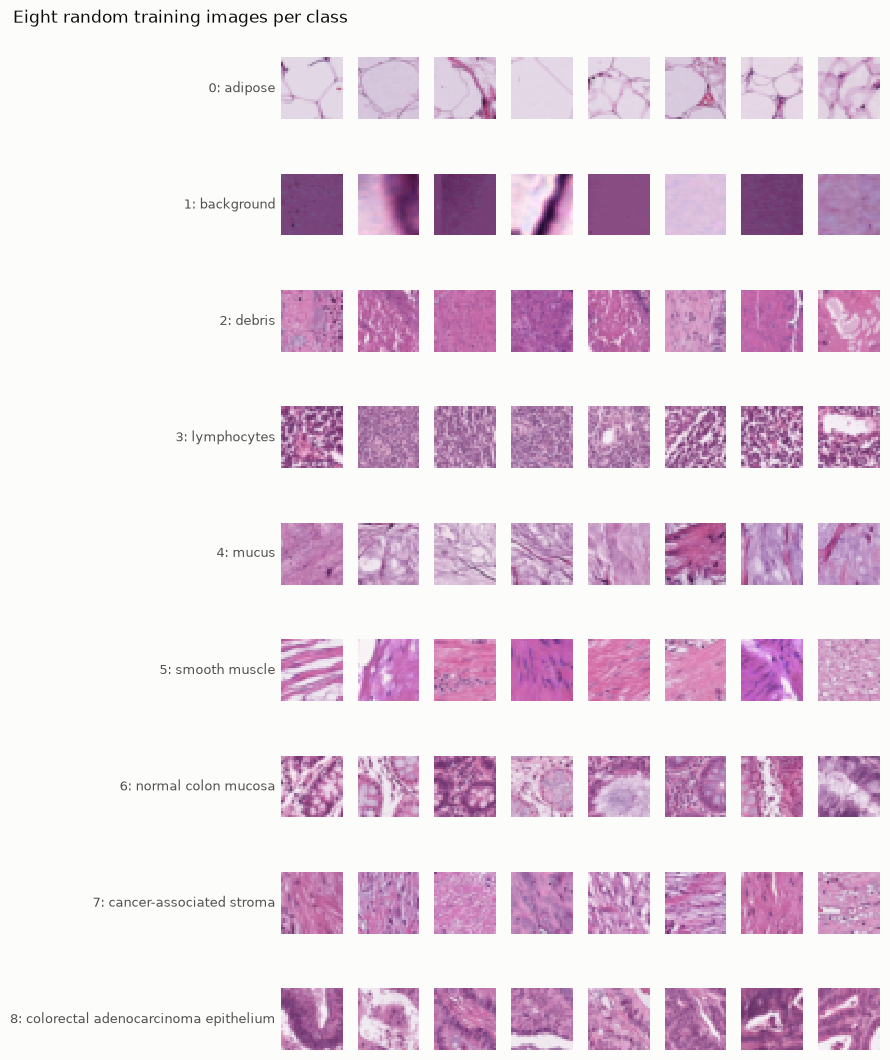

In [10]:
rng = np.random.default_rng(0)
n_examples = 8
train_images, train_labels = data["train"]

fig, axes = plt.subplots(len(CLASS_NAMES), n_examples, figsize=(9, 11))
for c, name in enumerate(CLASS_NAMES):
    idx = rng.choice(np.flatnonzero(train_labels == c), size=n_examples, replace=False)
    for j, i in enumerate(idx):
        ax = axes[c, j]
        ax.imshow(train_images[i], interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(False)
    axes[c, 0].set_ylabel(f"{c}: {name}", rotation=0, ha="right", va="center", fontsize=9)
fig.suptitle("Eight random training images per class", x=0.02, ha="left")
fig.tight_layout()
fig.savefig(FIGURES / "examples_per_class.png", dpi=150)
plt.show()

## Does the test set look like the training set?

The medmnist documentation says the training and validation images come from one dataset (NCT CRC HE 100K), while the **test images come from a different clinical center** (CRC VAL HE 7K). Different hospitals use slightly different staining chemicals, timings, and scanners, so their images can have a different overall color. This is called **stain variation**, and it is a real, common reason medical models do worse in a new hospital.

Below, each panel is one color channel. Each line shows how often each pixel value appears in a split. If the splits looked identical, the lines would sit on top of each other.

One caution before reading it: the class balance table above showed that the test set also has a **different mix of classes** (for example much more adipose). Adipose patches are mostly pale, so a different class mix alone would shift these curves. Any difference we see is a mix of two causes, class mix and staining, and this plot cannot separate them.

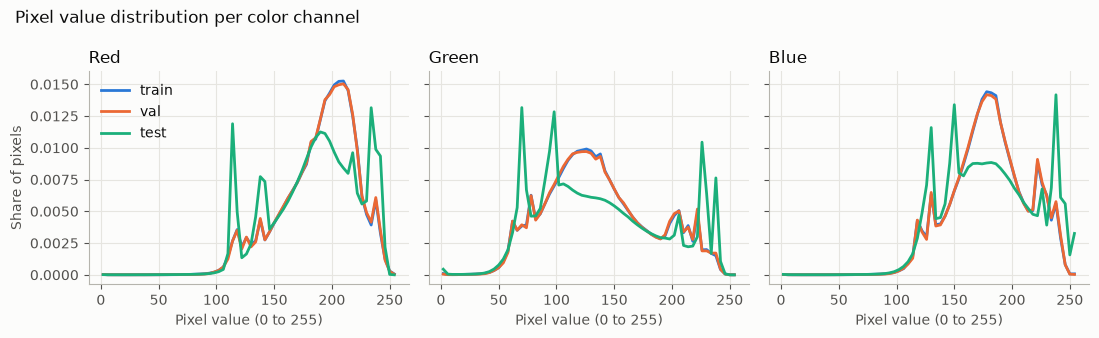

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
bins = np.arange(0, 257, 4)
for ch, (ax, ch_name) in enumerate(zip(axes, ["Red", "Green", "Blue"])):
    for split in SPLITS:
        values = data[split][0][..., ch].ravel()
        hist, edges = np.histogram(values, bins=bins, density=True)
        ax.plot(edges[:-1] + 2, hist, color=SPLIT_COLORS[split], linewidth=2, label=split)
    ax.set_title(ch_name, loc="left")
    ax.set_xlabel("Pixel value (0 to 255)")
axes[0].set_ylabel("Share of pixels")
axes[0].legend(frameon=False)
fig.suptitle("Pixel value distribution per color channel", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES / "pixel_histograms.png", dpi=150)
plt.show()

## What we found

* **Sizes:** 89,996 training, 10,004 validation, and 7,180 test images, each 28 by 28 pixels with 3 color channels stored as integers from 0 to 255.
* **Training classes are fairly balanced.** The most common class (adenocarcinoma epithelium, 14.3%) is only about 1.6 times as common as the least common (normal mucosa, 8.8%). So accuracy will not be badly fooled by one huge class, but we will still report macro F1 and per class recall, which weigh every class equally.
* **Validation looks just like training** (same percentages, same color statistics), because both were cut from the same source dataset.
* **The test set is different in two ways.** Its class mix differs (adipose 18.6% versus 10.4% in train, debris 4.7% versus 11.5%), and its pixel values are more spread out (standard deviation about 37 to 54 versus 31 to 45 in train). It comes from a different clinical center.
* **Why this matters for the project:** if the model scores much higher on validation than on test, this shift is the first suspect. It is also a small, real example of the problem Phase 3 is about: a model meeting data that is not quite like what it trained on.
* **"Background" is not always blank.** Many background patches are dark and blurry, not empty glass. Some could plausibly be confused with dense purple tissue such as lymphocytes.